In [ ]:
!pip install transformers
!pip install torch
!pip install pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 81.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 57.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 34.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 42.3 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.5.82
    Uninstalling nvidia-nvjitlink-cu12-12.5.82:
      Successfully uninstalled nvidia-nvjitlin

In [ ]:
# Step 1: Install TextBlob
!pip install textblob

# Step 2: Import libraries
import pandas as pd
import re
from textblob import TextBlob
import warnings
warnings.filterwarnings('ignore')

# Step 3: Read raw content of the file
# Since the CSV is malformed (no clean separation), we read it as text
with open('RedditNews.csv', 'r', encoding='utf-8') as f:
    lines = f.readlines()

print("First few lines of raw data:")
print("".join(lines[:2]) + "\n")

# Step 4: Parse lines and extract (date, headline) pairs
data = []
date_pattern = r'\d{4}-\d{2}-\d{2}'  # Match YYYY-MM-DD
current_date = None

for line in lines:
    # Split line into tokens (potential dates and headlines)
    tokens = re.split(r'(?=\d{4}-\d{2}-\d{2})', line.strip())

    for token in tokens:
        if not token:
            continue

        # Extract date at the beginning of token
        match = re.match(date_pattern, token)
        if match:
            current_date = match.group()
            # The rest is the headline
            headline = token[len(current_date):].strip()
        else:
            headline = token.strip()

        # Skip if no valid date or empty headline
        if not current_date or not headline:
            continue

        data.append({'Date': current_date, 'Headline': headline})

# Step 5: Create DataFrame
df = pd.DataFrame(data)
print(f"\n✅ Extracted {len(df)} headlines from {df['Date'].nunique()} unique days.")

# Step 6: Clean Headline column
def clean_headline(text):
    # Remove b'...' or b"..." wrapper
    text = re.sub(r"^b'(.*)'$", r"\1", text)
    text = re.sub(r'^b"(.*)"$', r'\1', text)
    # Remove escaped quotes and backslashes
    text = text.replace("\\'", "'").replace('\\"', '"').replace('\\\\', '\\')
    text = text.replace("\\r", " ").replace("\\n", " ").strip()
    return text

df['Headline'] = df['Headline'].astype(str).apply(clean_headline)

# Filter out placeholder-like or garbage
invalid = ['nan', '', 'b?', 'b', '""', "''"]
df = df[~df['Headline'].isin(invalid)]
df = df[df['Headline'].str.len() > 5]

# Step 7: Sentiment analysis function
def get_sentiment(text):
    return TextBlob(text).sentiment.polarity  # Returns -1 to 1

print("\n🧠 Computing sentiment for each headline...")
df['Sentiment'] = df['Headline'].apply(get_sentiment)

# Step 8: Group by Date → average sentiment
daily_sentiment = df.groupby('Date')['Sentiment'].mean().reset_index()
daily_sentiment.rename(columns={'Sentiment': 'Daily_Sentiment'}, inplace=True)
daily_sentiment['Date'] = pd.to_datetime(daily_sentiment['Date'])  # Ensure proper date type

# Sort by date
daily_sentiment.sort_values('Date', inplace=True)
daily_sentiment.reset_index(drop=True, inplace=True)

# Step 9: Display results
print("\n📅 Sample Daily Sentiment (first 10 days):")
print(daily_sentiment.head(10))

print("\n📊 Daily Sentiment Statistics:")
print(daily_sentiment['Daily_Sentiment'].describe())

# Step 10: Save and download
output_file = 'RedditNews_Daily_Sentiment.csv'
daily_sentiment.to_csv(output_file, index=False, encoding='utf-8')
print(f"\n📁 Saved daily sentiment to: {output_file}")

# Optional: Download in Colab
from google.colab import files
files.download(output_file)

First few lines of raw data:
Date,News
2016-07-01,"A 117-year-old woman in Mexico City finally received her birth certificate, and died a few hours later. Trinidad Alvarez Lira had waited years for proof that she had been born in 1898."



✅ Extracted 76105 headlines from 2943 unique days.

🧠 Computing sentiment for each headline...

📅 Sample Daily Sentiment (first 10 days):
        Date  Daily_Sentiment
0 2008-06-08        -0.032892
1 2008-06-09         0.026156
2 2008-06-10        -0.029106
3 2008-06-11        -0.014500
4 2008-06-12         0.036611
5 2008-06-13         0.069818
6 2008-06-14        -0.008545
7 2008-06-15        -0.008496
8 2008-06-16         0.009005
9 2008-06-17         0.089502

📊 Daily Sentiment Statistics:
count    2943.000000
mean        0.012099
std         0.040681
min        -0.166995
25%        -0.014223
50%         0.012033
75%         0.038613
max         0.197128
Name: Daily_Sentiment, dtype: float64

📁 Saved daily sentiment to: RedditNews_Daily_Sentiment

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

In [ ]:
start = '2008-06-08'
end ='2016-07-01'

stock ='GOOG'
data = yf.download(stock, start=start, end=end)

# Save to CSV
data.to_csv('GOOG_2008-2016.csv')
print("Data downloaded and saved to GOOG_2008-2016.csv")

[*********************100%***********************]  1 of 1 completed

Data downloaded and saved to GOOG_2008-2016.csv


In [ ]:
data

Price,Close,High,Low,Open,Volume
Ticker,GOOG,GOOG,GOOG,GOOG,GOOG
Date,,,,,
2008-06-09,13.812565,14.112898,13.503815,14.064865,212324874
2008-06-10,13.720956,13.836088,13.537983,13.606814,146844353
2008-06-11,13.498861,13.799442,13.480540,13.772207,153087667
2008-06-12,13.690750,13.815785,13.540459,13.587008,220487355
2008-06-13,14.150284,14.254026,13.898480,13.902193,248303226
...,...,...,...,...,...
2016-06-24,33.561504,34.266314,33.473526,33.559017,88980000
2016-06-27,33.215561,33.416371,32.968233,33.351752,52580000


In [ ]:
import pandas as pd

# Load the datasets
try:
    df_reddit = pd.read_csv('RedditNews_Daily_Sentiment.csv')
    df_goog = pd.read_csv('GOOG_2008-2016.csv')
except FileNotFoundError as e:
    print(f"Error loading file: {e}. Please ensure the files are uploaded to your Colab environment.")
    exit()

# Preprocess GOOG data
# Drop the first two rows (redundant headers)
df_goog = df_goog.iloc[2:].copy()

# Rename the first column to 'Date' for merging
df_goog.rename(columns={df_goog.columns[0]: 'Date'}, inplace=True)

# Convert 'Date' columns to datetime objects for accurate merging
df_reddit['Date'] = pd.to_datetime(df_reddit['Date'])
df_goog['Date'] = pd.to_datetime(df_goog['Date'])

# Merge the two DataFrames based on the 'Date' column
merged_df = pd.merge(df_goog, df_reddit, on='Date', how='left')

# Handle missing values in 'Daily_Sentiment' column
# It's good practice to inspect how many missing values are there before filling
print("Number of missing values in 'Daily_Sentiment' before handling:")
print(merged_df['Daily_Sentiment'].isnull().sum())

# For simplicity, we'll fill missing sentiment values with 0,
# assuming no sentiment data implies a neutral sentiment.
# You might choose a different strategy based on your analysis needs (e.g., forward fill, mean)
merged_df['Daily_Sentiment'].fillna(0, inplace=True)

print("\nNumber of missing values in 'Daily_Sentiment' after handling:")
print(merged_df['Daily_Sentiment'].isnull().sum())

# Display the first few rows of the merged DataFrame
print("\nFirst 5 rows of the merged DataFrame:")
print(merged_df.head())

# Display information about the merged DataFrame to confirm data types and non-null counts
print("\nInformation about the merged DataFrame:")
print(merged_df.info())

# Optionally, save the merged DataFrame to a new CSV file
merged_df.to_csv('GOOG_with_Sentiment.csv', index=False)
print("\nMerged DataFrame saved to 'GOOG_with_Sentiment.csv'")

Number of missing values in 'Daily_Sentiment' before handling:
0

Number of missing values in 'Daily_Sentiment' after handling:
0

First 5 rows of the merged DataFrame:
        Date               Close                High                 Low  \
0 2008-06-09  13.812564849853516  14.112897931318704  13.503815077739997   
1 2008-06-10  13.720955848693848  13.836087606589356  13.537983364663686   
2 2008-06-11  13.498861312866211  13.799441805603676  13.480539511908509   
3 2008-06-12  13.690750122070312  13.815785102179868  13.540459380480423   
4 2008-06-13  14.150283813476562  14.254025822950673  13.898479920264851   

                 Open     Volume  Daily_Sentiment  
0  14.064864585025797  212324874         0.026156  
1  13.606813843562977  146844353        -0.029106  
2  13.772206542335908  153087667        -0.014500  
3  13.587008100025637  220487355         0.036611  
4  13.902193388948461  248303226         0.069818  

Information about the merged DataFrame:
<class 'pandas.core.f

In [ ]:
import pandas as pd

# --- Step 1: Load the datasets ---
try:
    df_reddit = pd.read_csv('RedditNews_Daily_Sentiment.csv')
    df_goog = pd.read_csv('GOOG_2008-2016.csv')
    print("Datasets loaded successfully.")
except FileNotFoundError as e:
    print(f"Error loading file: {e}. Please ensure the files are uploaded to your Colab environment.")
    exit()

# --- Step 2: Preprocess GOOG Data ---
# Drop the first two rows (redundant headers) from GOOG data
df_goog = df_goog.iloc[2:].copy()
print("Dropped redundant header rows from GOOG data.")

# Rename the first column to 'Date' for merging
df_goog.rename(columns={df_goog.columns[0]: 'Date'}, inplace=True)
print("Renamed first column of GOOG data to 'Date'.")

# Convert 'Date' columns to datetime objects for accurate merging
df_reddit['Date'] = pd.to_datetime(df_reddit['Date'])
df_goog['Date'] = pd.to_datetime(df_goog['Date'])
print("Converted 'Date' columns to datetime format.")

# --- Step 3: Merge DataFrames ---
# Merge GOOG data with Reddit sentiment data based on the 'Date' column
# 'how='left'' ensures all GOOG dates are kept, filling NaN for unmatched sentiment dates
merged_df = pd.merge(df_goog, df_reddit, on='Date', how='left')
print("Merged GOOG data with Reddit sentiment data.")

# Handle missing values in 'Daily_Sentiment' column
# Fill NaN values (where no sentiment data exists for a date) with 0, assuming neutral sentiment.
# Consider other imputation strategies (e.g., forward fill, mean) if your analysis requires.
initial_nulls = merged_df['Daily_Sentiment'].isnull().sum()
merged_df['Daily_Sentiment'].fillna(0, inplace=True)
print(f"Filled {initial_nulls} missing sentiment values with 0.")

# --- Step 4: Add 'tomorrow's closing value' as the output feature ---
# Create the 'tomorrow's closing value' column by shifting the 'Close' column upwards by 1
# This makes the closing value of the next day the target for the current day's features.
merged_df['tomorrow\'s closing value'] = merged_df['Close'].shift(-1)
print("Added 'tomorrow\'s closing value' column by shifting 'Close' prices.")

# Handle the last cell of the 'tomorrow's closing value' column
# The last value will be NaN after the shift. As requested, we fill it
# with the 'Close' value from the second-to-last day (previous 2 value).
if not merged_df.empty and pd.isna(merged_df.iloc[-1]['tomorrow\'s closing value']):
    if len(merged_df) >= 2:
        # Fill the last row's 'tomorrow\'s closing value' with the 'Close' of the second to last day
        merged_df.loc[merged_df.index[-1], 'tomorrow\'s closing value'] = merged_df.iloc[-2]['Close']
        print("Filled the last 'tomorrow\'s closing value' with the 'Close' price from the second to last day.")
    elif len(merged_df) == 1:
        # Edge case: if only one row, fill with its own close value.
        merged_df.loc[merged_df.index[-1], 'tomorrow\'s closing value'] = merged_df.iloc[-1]['Close']
        print("Dataset has only one row; filled 'tomorrow\'s closing value' with current day's 'Close'.")

# --- Step 5: Display and Save Results ---
print("\n--- Processed DataFrame Overview ---")
print("First 5 rows:")
print(merged_df.head())

print("\nLast 5 rows:")
print(merged_df.tail())

print("\nDataFrame Information (dtypes and non-null counts):")
print(merged_df.info())

# Optionally, save the final processed DataFrame to a new CSV file
output_filename = 'GOOG_with_Tomorrow_Close_Final.csv'
merged_df.to_csv(output_filename, index=False)
print(f"\nFinal processed DataFrame saved to '{output_filename}'")


Datasets loaded successfully.
Dropped redundant header rows from GOOG data.
Renamed first column of GOOG data to 'Date'.
Converted 'Date' columns to datetime format.
Merged GOOG data with Reddit sentiment data.
Filled 0 missing sentiment values with 0.
Added 'tomorrow's closing value' column by shifting 'Close' prices.
Filled the last 'tomorrow's closing value' with the 'Close' price from the second to last day.

--- Processed DataFrame Overview ---
First 5 rows:
        Date               Close                High                 Low  \
0 2008-06-09  13.812564849853516  14.112897931318704  13.503815077739997   
1 2008-06-10  13.720955848693848  13.836087606589356  13.537983364663686   
2 2008-06-11  13.498861312866211  13.799441805603676  13.480539511908509   
3 2008-06-12  13.690750122070312  13.815785102179868  13.540459380480423   
4 2008-06-13  14.150283813476562  14.254025822950673  13.898479920264851   

                 Open     Volume  Daily_Sentiment tomorrow's closing value 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb
from keras.models import Sequential
from keras.layers import Dense, LSTM

import warnings
warnings.filterwarnings("ignore")


In [ ]:
# Load your dataset
df = pd.read_csv('GOOG_with_Tomorrow_Close_Final.csv')

# Drop 'Date' column and split features/target
X = df.drop(columns=['Date', "tomorrow's closing value"])
y = df["tomorrow's closing value"]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, shuffle=False
)


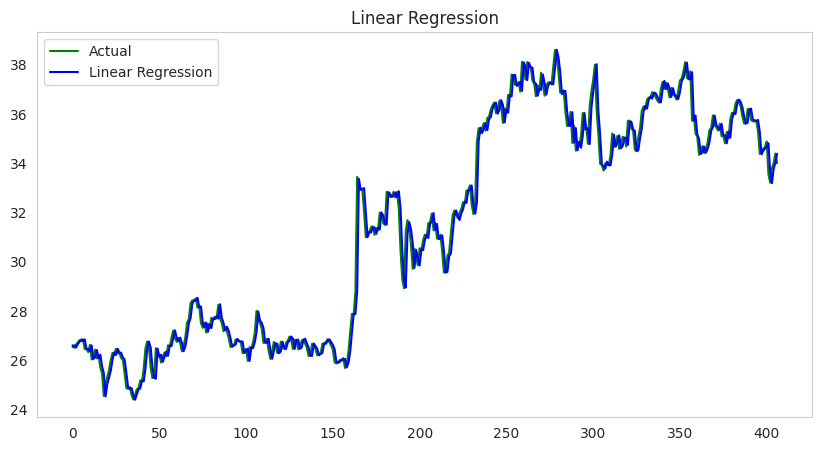

In [ ]:
# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

# Evaluation
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))
lr_mae = mean_absolute_error(y_test, lr_preds)
lr_r2 = r2_score(y_test, lr_preds)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(lr_preds, label='Linear Regression', color='blue')
plt.legend(); plt.title("Linear Regression")
plt.grid(); plt.show()


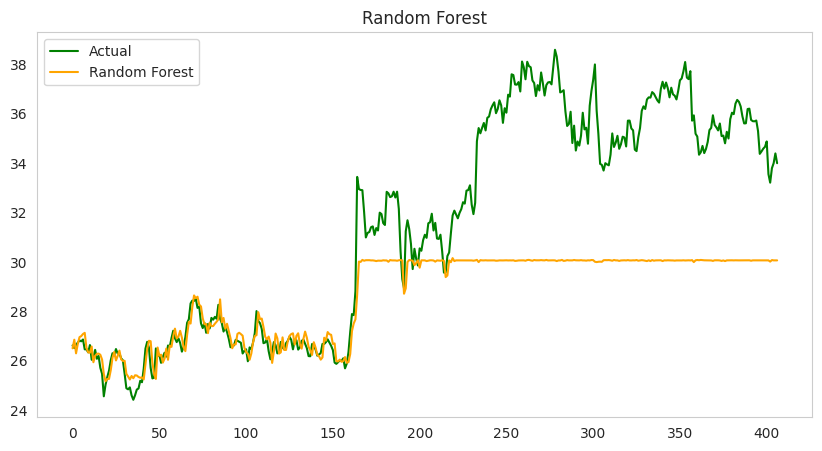

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_r2 = r2_score(y_test, rf_preds)

plt.figure(figsize=(10, 5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(rf_preds, label='Random Forest', color='orange')
plt.legend(); plt.title("Random Forest")
plt.grid(); plt.show()


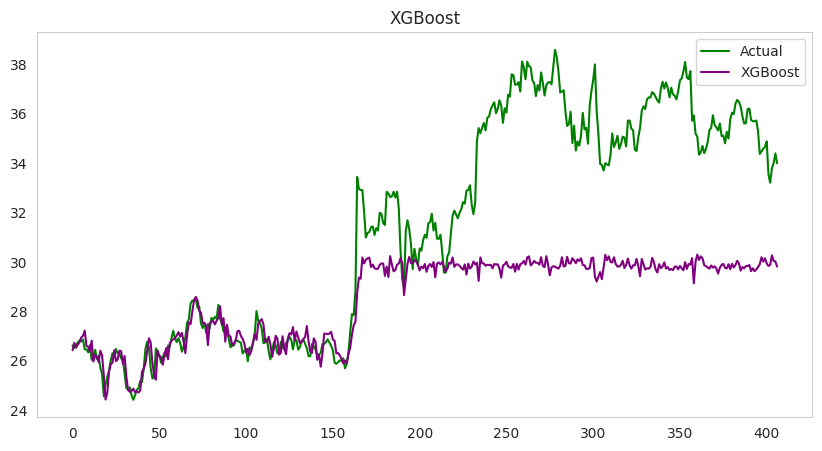

In [ ]:
xgb_model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
xgb_mae = mean_absolute_error(y_test, xgb_preds)
xgb_r2 = r2_score(y_test, xgb_preds)

plt.figure(figsize=(10, 5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(xgb_preds, label='XGBoost', color='purple')
plt.legend(); plt.title("XGBoost")
plt.grid(); plt.show()


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


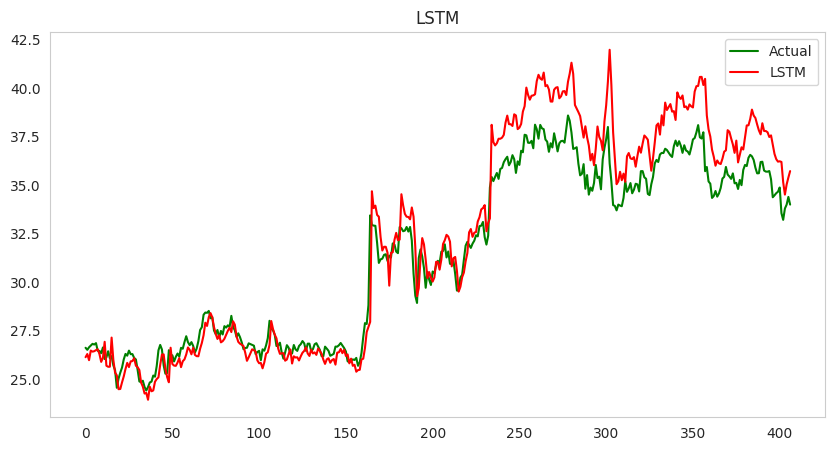

In [ ]:
# Reshape for LSTM (samples, time_steps, features)
X_lstm = X_scaled.reshape((X_scaled.shape[0], 1, X_scaled.shape[1]))

# Train/test split for LSTM
X_lstm_train, X_lstm_test = X_lstm[:int(0.8*len(X_lstm))], X_lstm[int(0.8*len(X_lstm)):]
y_lstm_train, y_lstm_test = y[:int(0.8*len(y))], y[int(0.8*len(y)):]

# Build LSTM model
lstm_model = Sequential()
lstm_model.add(LSTM(50, activation='relu', input_shape=(1, X.shape[1])))
lstm_model.add(Dense(1))
lstm_model.compile(optimizer='adam', loss='mse')

# Train LSTM
lstm_model.fit(X_lstm_train, y_lstm_train, epochs=50, verbose=0)

# Predict
lstm_preds = lstm_model.predict(X_lstm_test).flatten()

# Evaluation
lstm_rmse = np.sqrt(mean_squared_error(y_lstm_test, lstm_preds))
lstm_mae = mean_absolute_error(y_lstm_test, lstm_preds)
lstm_r2 = r2_score(y_lstm_test, lstm_preds)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(y_lstm_test.values, label='Actual', color='green')
plt.plot(lstm_preds, label='LSTM', color='red')
plt.legend(); plt.title("LSTM")
plt.grid(); plt.show()


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


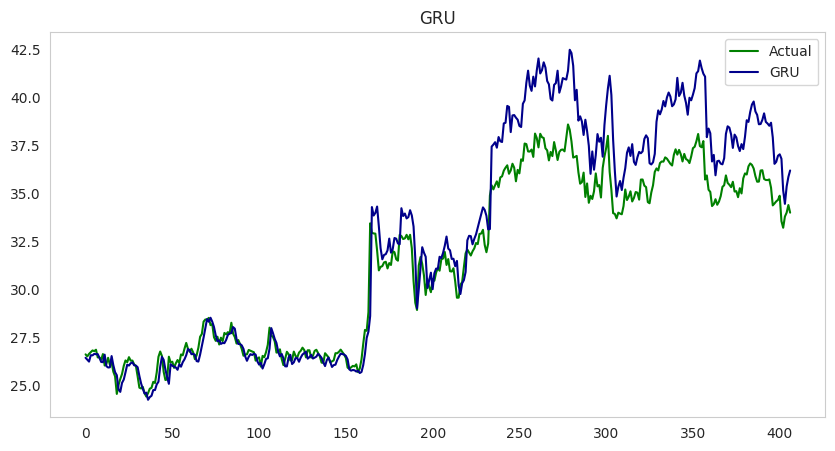

In [ ]:
from keras.layers import GRU

# Build GRU model
gru_model = Sequential()
gru_model.add(GRU(50, activation='relu', input_shape=(1, X.shape[1])))
gru_model.add(Dense(1))
gru_model.compile(optimizer='adam', loss='mse')

# Train GRU
gru_model.fit(X_lstm_train, y_lstm_train, epochs=50, verbose=0)

# Predict
gru_preds = gru_model.predict(X_lstm_test).flatten()

# Evaluation
gru_rmse = np.sqrt(mean_squared_error(y_lstm_test, gru_preds))
gru_mae = mean_absolute_error(y_lstm_test, gru_preds)
gru_r2 = r2_score(y_lstm_test, gru_preds)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(y_lstm_test.values, label='Actual', color='green')
plt.plot(gru_preds, label='GRU', color='darkblue')
plt.legend(); plt.title("GRU")
plt.grid(); plt.show()


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


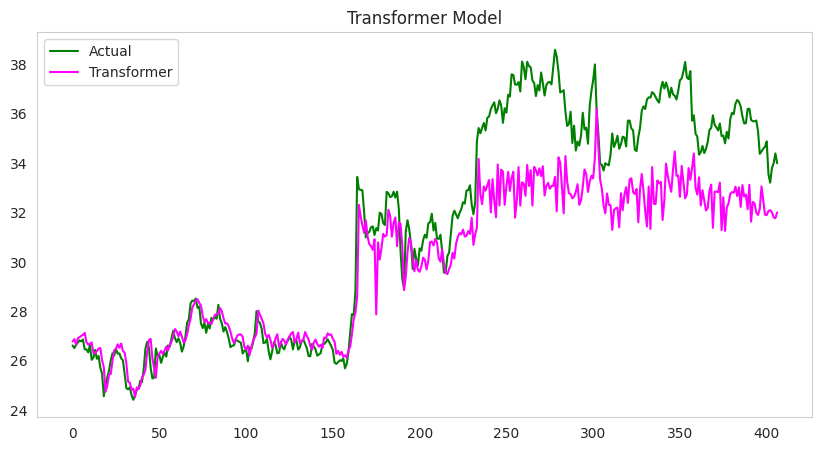

In [ ]:
import tensorflow as tf
from keras.layers import Input, Dense, LayerNormalization, MultiHeadAttention, Dropout
from keras.models import Model

# Prepare transformer inputs
X_tf_train = X_lstm_train
X_tf_test = X_lstm_test

# Define transformer block
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0):
    x = MultiHeadAttention(key_dim=head_size, num_heads=num_heads)(inputs, inputs)
    x = Dropout(dropout)(x)
    x = LayerNormalization(epsilon=1e-6)(x)
    res = x + inputs

    x = Dense(ff_dim, activation="relu")(res)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    x = LayerNormalization(epsilon=1e-6)(x)
    return x + res

# Transformer architecture
input_layer = Input(shape=(1, X.shape[1]))
x = transformer_encoder(input_layer, head_size=64, num_heads=2, ff_dim=64, dropout=0.1)
x = Flatten()(x)
x = Dense(50, activation='relu')(x)
output = Dense(1)(x)

transformer_model = Model(inputs=input_layer, outputs=output)
transformer_model.compile(optimizer='adam', loss='mse')

# Train transformer
transformer_model.fit(X_tf_train, y_lstm_train, epochs=50, verbose=0)

# Predict
transformer_preds = transformer_model.predict(X_tf_test).flatten()

# Evaluation
tf_rmse = np.sqrt(mean_squared_error(y_lstm_test, transformer_preds))
tf_mae = mean_absolute_error(y_lstm_test, transformer_preds)
tf_r2 = r2_score(y_lstm_test, transformer_preds)

# Plot
plt.figure(figsize=(10, 5))
plt.plot(y_lstm_test.values, label='Actual', color='green')
plt.plot(transformer_preds, label='Transformer', color='magenta')
plt.legend(); plt.title("Transformer Model")
plt.grid(); plt.show()


In [ ]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression', 'Random Forest', 'XGBoost',
        'LSTM', 'GRU', 'Transformer'
    ],
    'RMSE': [
        lr_rmse, rf_rmse, xgb_rmse,
        lstm_rmse,  gru_rmse, tf_rmse
    ],
    'MAE': [
        lr_mae, rf_mae, xgb_mae,
        lstm_mae, gru_mae, tf_mae
    ],
    'R2 Score': [
        lr_r2, rf_r2, xgb_r2,
        lstm_r2,  gru_r2, tf_r2
    ]
})

print(results)


               Model      RMSE       MAE  R2 Score
0  Linear Regression  0.532816  0.353955  0.985387
1      Random Forest  4.023081  2.934377  0.166864
2            XGBoost  4.165653  3.041879  0.106768
3               LSTM  1.559397  1.208873  0.874827
4                GRU  1.959703  1.460650  0.802313
5        Transformer  2.245250  1.643080  0.740506


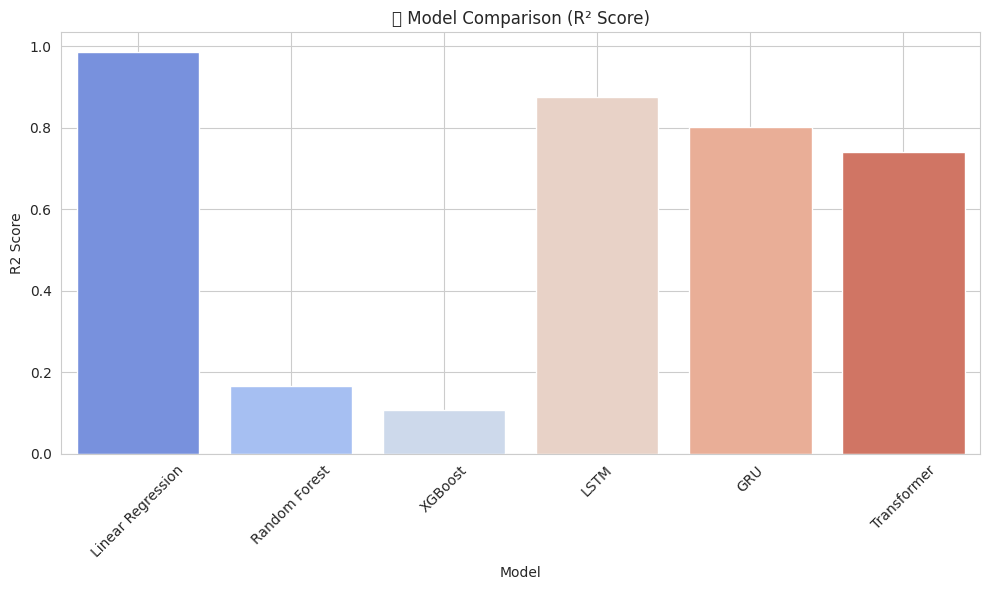

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='R2 Score', data=results, palette='coolwarm')
plt.title("📊 Model Comparison (R² Score)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb
from keras.models import Sequential, Model
from keras.layers import Dense, LSTM, GRU, Input, Flatten, Dropout, LayerNormalization, MultiHeadAttention
from keras.optimizers import Adam

import warnings
warnings.filterwarnings('ignore')


In [ ]:
# without sentiment analysis

In [ ]:
# Load dataset
df = pd.read_csv('GOOG_with_Tomorrow_Close_Final.csv')

# Drop unnecessary columns
df = df.drop(columns=['Date', 'Daily_Sentiment'])

# Split input and target
X = df.drop(columns=["tomorrow's closing value"])
y = df["tomorrow's closing value"]

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, shuffle=False
)

# For LSTM/GRU/Transformer reshape (samples, time_step, features)
X_lstm_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_lstm_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))


In [ ]:
df.head()

,Close,High,Low,Open,Volume,tomorrow's closing value
0,13.812565,14.112898,13.503815,14.064865,212324874,13.720956
1,13.720956,13.836088,13.537983,13.606814,146844353,13.498861
2,13.498861,13.799442,13.480540,13.772207,153087667,13.690750
3,13.690750,13.815785,13.540459,13.587008,220487355,14.150284
4,14.150284,14.254026,13.898480,13.902193,248303226,14.182473


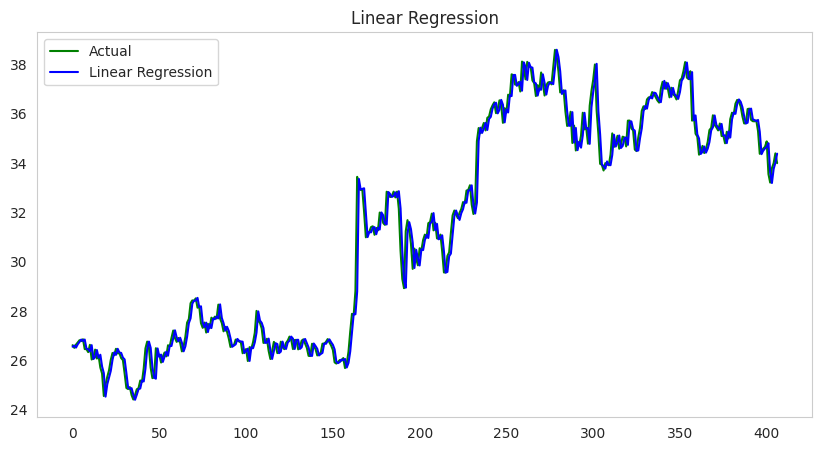

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_preds))
lr_mae = mean_absolute_error(y_test, lr_preds)
lr_r2 = r2_score(y_test, lr_preds)

plt.figure(figsize=(10,5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(lr_preds, label='Linear Regression', color='blue')
plt.legend(); plt.title('Linear Regression'); plt.grid(); plt.show()


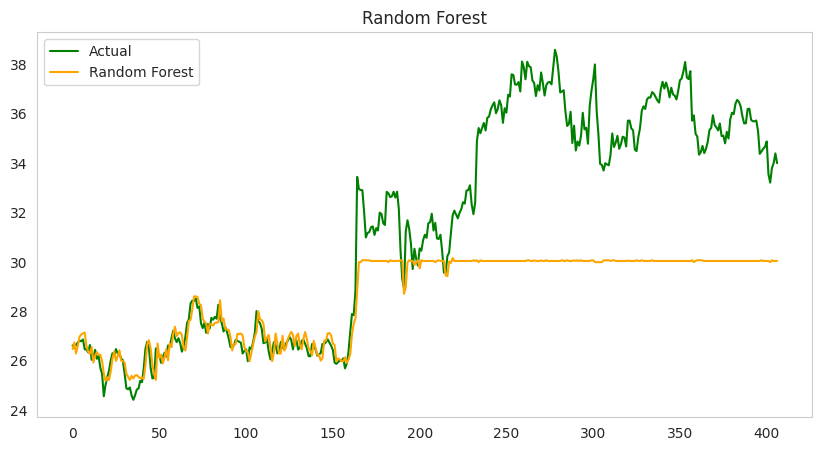

In [ ]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_preds))
rf_mae = mean_absolute_error(y_test, rf_preds)
rf_r2 = r2_score(y_test, rf_preds)

plt.figure(figsize=(10,5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(rf_preds, label='Random Forest', color='orange')
plt.legend(); plt.title('Random Forest'); plt.grid(); plt.show()


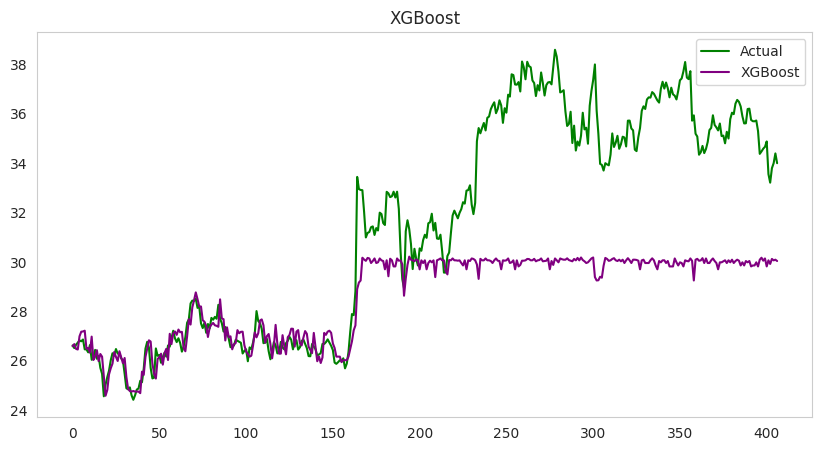

In [ ]:
xgb_model = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
xgb_mae = mean_absolute_error(y_test, xgb_preds)
xgb_r2 = r2_score(y_test, xgb_preds)

plt.figure(figsize=(10,5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(xgb_preds, label='XGBoost', color='purple')
plt.legend(); plt.title('XGBoost'); plt.grid(); plt.show()


13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step


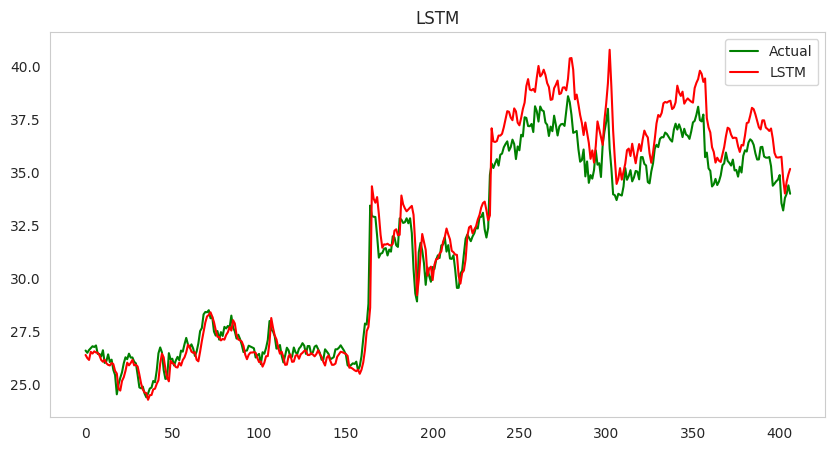

In [ ]:
lstm_model = Sequential()
lstm_model.add(LSTM(50, activation='relu', input_shape=(1, X.shape[1])))
lstm_model.add(Dense(1))
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.fit(X_lstm_train, y_train, epochs=50, verbose=0)

lstm_preds = lstm_model.predict(X_lstm_test).flatten()

lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_preds))
lstm_mae = mean_absolute_error(y_test, lstm_preds)
lstm_r2 = r2_score(y_test, lstm_preds)

plt.figure(figsize=(10,5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(lstm_preds, label='LSTM', color='red')
plt.legend(); plt.title('LSTM'); plt.grid(); plt.show()


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


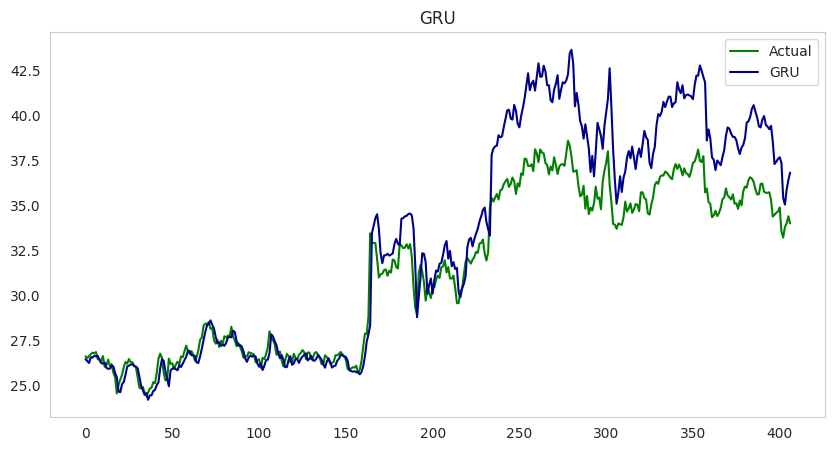

In [ ]:
gru_model = Sequential()
gru_model.add(GRU(50, activation='relu', input_shape=(1, X.shape[1])))
gru_model.add(Dense(1))
gru_model.compile(optimizer='adam', loss='mse')
gru_model.fit(X_lstm_train, y_train, epochs=50, verbose=0)

gru_preds = gru_model.predict(X_lstm_test).flatten()

gru_rmse = np.sqrt(mean_squared_error(y_test, gru_preds))
gru_mae = mean_absolute_error(y_test, gru_preds)
gru_r2 = r2_score(y_test, gru_preds)

plt.figure(figsize=(10,5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(gru_preds, label='GRU', color='darkblue')
plt.legend(); plt.title('GRU'); plt.grid(); plt.show()


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step


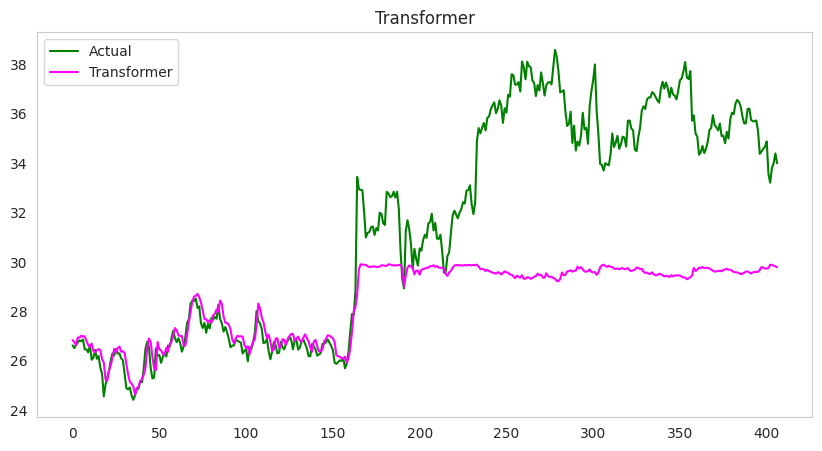

In [ ]:
def transformer_encoder(inputs, head_size, num_heads, ff_dim, dropout=0.1):
    x = MultiHeadAttention(num_heads=num_heads, key_dim=head_size)(inputs, inputs)
    x = Dropout(dropout)(x)
    x = LayerNormalization(epsilon=1e-6)(x)
    res = x + inputs

    x = Dense(ff_dim, activation="relu")(res)
    x = Dropout(dropout)(x)
    x = Dense(inputs.shape[-1])(x)
    return LayerNormalization(epsilon=1e-6)(x + res)

input_layer = Input(shape=(1, X.shape[1]))
x = transformer_encoder(input_layer, head_size=64, num_heads=2, ff_dim=64)
x = Flatten()(x)
x = Dense(64, activation='relu')(x)
output = Dense(1)(x)

transformer_model = Model(inputs=input_layer, outputs=output)
transformer_model.compile(optimizer=Adam(learning_rate=1e-3), loss='mse')
transformer_model.fit(X_lstm_train, y_train, epochs=50, verbose=0)

transformer_preds = transformer_model.predict(X_lstm_test).flatten()

tf_rmse = np.sqrt(mean_squared_error(y_test, transformer_preds))
tf_mae = mean_absolute_error(y_test, transformer_preds)
tf_r2 = r2_score(y_test, transformer_preds)

plt.figure(figsize=(10,5))
plt.plot(y_test.values, label='Actual', color='green')
plt.plot(transformer_preds, label='Transformer', color='magenta')
plt.legend(); plt.title('Transformer'); plt.grid(); plt.show()


In [ ]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost', 'LSTM', 'GRU', 'Transformer'],
    'RMSE': [lr_rmse, rf_rmse, xgb_rmse, lstm_rmse, gru_rmse, tf_rmse],
    'MAE': [lr_mae, rf_mae, xgb_mae, lstm_mae, gru_mae, tf_mae],
    'R2 Score': [lr_r2, rf_r2, xgb_r2, lstm_r2, gru_r2, tf_r2]
})

print(results)


               Model      RMSE       MAE  R2 Score
0  Linear Regression  0.533128  0.353921  0.985369
1      Random Forest  4.035164  2.943973  0.161853
2            XGBoost  4.072319  2.978446  0.146347
3               LSTM  1.145037  0.870444  0.932510
4                GRU  2.503993  1.862042  0.677251
5        Transformer  4.349254  3.167739  0.026295


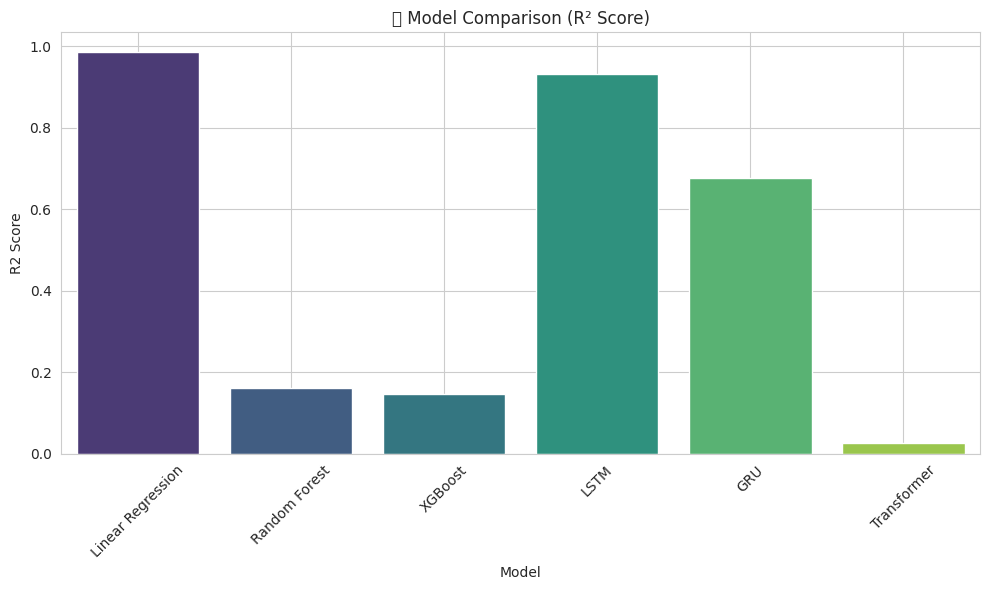

In [ ]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='R2 Score', data=results, palette='viridis')
plt.title("📊 Model Comparison (R² Score)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()
